In [ ]:
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.collections import PatchCollection
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath


BASE_DIR   = Path("")

RAW_DIR = BASE_DIR / "Data" / "Raw"
FINAL_DIR = BASE_DIR / "Data" / "Final"

MODEL_DIR  = BASE_DIR / "Models" / "Primary_NB2"

TABLES_DIR = BASE_DIR / "Tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

FIGURES_DIR = BASE_DIR / "Figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Descriptives

In [18]:
df_full = pd.read_parquet(FINAL_DIR / "df_full_modelling.parquet")

DF    = df_full
CODE  = "BNF_CHEMICAL_SUBSTANCE_CODE"
ITEMS = "ITEMS"
COST  = "ACTUAL_COST"        
PRAC  = "PRACTICE_CODE"
KEY   = [PRAC, "YEAR_MONTH_DATE"]

OUT_FILE  = TABLES_DIR / "descriptives.tex"
CODE_FILE = TABLES_DIR / "descriptives_codes.tex"     # appendix table of BNF codes

CAPTION   = "Descriptive statistics by disease, drug class and substance"
LABEL     = "tab:descriptives"
FONT      = r"\footnotesize"       # "" for normal size
PLACEMENT = "htbp"

# Columns, in order
COLUMNS = [
    ("n_prac",       "Practices",         "Sample"),
    ("items",        "Total items",       "Sample"),
    ("pct_zero",     r"\% zero",          "Practice-months"),
    ("mean_all",     "Mean",              "Practice-months"),
    ("sd_all",       "SD",                "Practice-months"),
    ("mean_pos",     r"Mean ($>0$)",      "Practice-months"),
    ("sd_pos",       r"SD ($>0$)",        "Practice-months"),
    ("vmr_pos",      r"Var/Mean ($>0$)",  "Practice-months"),
    ("total_cost_m", r"Total (\pounds m)", "Cost"),
    ("cost_item",    r"Per item (\pounds)", "Cost"),
]


DECIMALS = {"n_rows": 0, "n_prac": 0, "items": 0, "pct_pos": 1, "pct_zero": 1,
            "mean_all": 2, "sd_all": 2, "median_all": 2, "mean_pos": 2, "sd_pos": 2,
            "vmr_pos": 2, "total_cost_m": 2, "cost_item": 2}

# ==========================================================================
# 2. HIERARCHY (same as before)
# ==========================================================================
sub = {
 "Donepezil": ["0411000D0"], "Galantamine": ["0411000E0"], "Rivastigmine": ["0411000F0"],
 "Memantine Hydrochloride": ["0411000G0"],
 "Benztropine mesilate": ["0409020E0"], "Biperiden hydrochloride": ["0409020G0"],
 "Trihexyphenidyl": ["0409020C0"], "Procyclidine": ["0409020S0"], "Orphenadrine": ["0409020N0"],
 "Co-beneldopa": ["0409010K0"], "Co-careldopa": ["0409010N0"],
 "Levodopa with carbidopa and entacapone": ["0409010X0"], "Carbidopa": ["0409010D0"], "Levodopa": ["0409010I0"],
 "Cabergoline": ["0409010U0"], "Apomorphine Hydrochloride": ["0409010A0"],
 "Pramipexole": ["0409010W0"], "Ropinirole Hydrochloride": ["0409010H0"], "Rotigotine": ["0409010Z0"],
 "Entacapone": ["0409010V0"], "Opicapone": ["0409010AB"], "Tolcapone": ["0409010S0"],
 "Rasagiline mesylate": ["0409010Y0"], "Safinamide": ["0409010AA"], "Selegiline hydrochloride": ["0409010T0"],
 "Amantadine Hydrochloride": ["0409010B0"],
}
def c(*names): return [x for n in names for x in sub[n]]

classes = {
 "AChEIs": ["Donepezil","Galantamine","Rivastigmine"],
 "Anticholinergics": ["Benztropine mesilate","Biperiden hydrochloride","Trihexyphenidyl","Procyclidine","Orphenadrine"],
 "Dopamine precursors": ["Co-beneldopa","Co-careldopa","Levodopa with carbidopa and entacapone","Carbidopa","Levodopa"],
 "Dopamine agonists": ["Cabergoline","Apomorphine Hydrochloride","Pramipexole","Ropinirole Hydrochloride","Rotigotine"],
 "COMT inhibitors": ["Entacapone","Opicapone","Tolcapone"],
 "MAO-B inhibitors": ["Rasagiline mesylate","Safinamide","Selegiline hydrochloride"],
}
PD_CLASSES = ["Anticholinergics","Dopamine precursors","Dopamine agonists","COMT inhibitors","MAO-B inhibitors"]


layout = [(0, "Dementia", classes["AChEIs"] + ["Memantine Hydrochloride"])]
layout += [(1, "AChEIs", classes["AChEIs"])] + [(2, n, [n]) for n in classes["AChEIs"]]
layout += [(1, "NMDA receptor antagonists (memantine)", ["Memantine Hydrochloride"])]
pd_all = sum([classes[k] for k in PD_CLASSES], []) + ["Amantadine Hydrochloride"]
layout += [(0, "Parkinson's disease", pd_all)]
for k in PD_CLASSES:
    layout += [(1, k, classes[k])] + [(2, n, [n]) for n in classes[k]]
layout += [(1, "NMDA receptor antagonists (amantadine)", ["Amantadine Hydrochloride"])]


if not COST:
    COLUMNS = [col for col in COLUMNS if col[0] not in ("total_cost_m", "cost_item")]

def esc(s):
    return str(s).replace("&", r"\&").replace("%", r"\%").replace("#", r"\#").replace("_", r"\_")

def stats(names):
    codes = c(*names)
    d = DF[DF[CODE].isin(codes)]
    agg = {"items": (ITEMS, "sum")}
    if COST: agg["cost"] = (COST, "sum")
    g = d.groupby(KEY).agg(**agg)
    x = g["items"]; pos = x[x > 0]
    var_pos = pos.var(ddof=1) if len(pos) > 1 else np.nan
    tot = x.sum()
    out = {
        "n_rows": len(x), "n_prac": d[PRAC].nunique(), "items": tot,
        "pct_pos": (x > 0).mean() * 100, "pct_zero": (x == 0).mean() * 100,
        "mean_all": x.mean(), "sd_all": x.std(ddof=1), "median_all": x.median(),
        "mean_pos": pos.mean(), "sd_pos": np.sqrt(var_pos) if pd.notna(var_pos) else np.nan,
        "vmr_pos": var_pos / pos.mean() if len(pos) > 1 and pos.mean() else np.nan,
    }
    if COST:
        out["total_cost_m"] = g["cost"].sum() / 1e6
        out["cost_item"] = g["cost"].sum() / tot if tot > 0 else np.nan
    return out

def fmt(key, v):
    return "--" if v is None or pd.isna(v) else f"{v:,.{DECIMALS[key]}f}"

keys = [k for k, _, _ in COLUMNS]
n = len(COLUMNS)

# group header row
groups, i = [], 0
while i < n:
    j = i
    while j + 1 < n and COLUMNS[j + 1][2] == COLUMNS[i][2]:
        j += 1
    groups.append((COLUMNS[i][2], i, j)); i = j + 1
has_groups = any(g for g, _, _ in groups)

n_total = DF.groupby(KEY).ngroups
n_prac_total = DF[PRAC].nunique()
note = (rf"\textit{{Notes:}} The unit of observation is the practice-month "
        rf"($N={n_total:,}$ practice-months, {n_prac_total:,} practices). "
        r"Mean and SD are over all practice-months, including months with no prescribing; "
        r"columns marked ($>0$) use only practice-months with at least one item. "
        r"Var/Mean is the variance-to-mean ratio of positive counts, where values well above 1 "
        r"indicate overdispersion. "
        + (r"Costs are actual cost in pounds sterling. " if COST else "") +
        r"Disease rows pool all substances beneath them.")

L = [rf"\begin{{table}}[{PLACEMENT}]", r"\centering", rf"\caption{{{CAPTION}}}", rf"\label{{{LABEL}}}"]
if FONT: L.append(FONT)
L += [r"\begin{adjustbox}{max width=\textwidth}", rf"\begin{{tabular}}{{l{'r' * n}}}", r"\toprule"]

if has_groups:
    cells, rules = [""], []
    for g, a, b in groups:
        cells.append(rf"\multicolumn{{{b - a + 1}}}{{c}}{{{g}}}" if g else "")
        if g: rules.append(rf"\cmidrule(lr){{{a + 2}-{b + 2}}}")
    L.append(" & ".join(cells) + r" \\")
    L.append("".join(rules))
L.append(" & ".join(["Substance / group"] + [h for _, h, _ in COLUMNS]) + r" \\")
L.append(r"\midrule")

for idx, (indent, lab, names) in enumerate(layout):
    if indent == 0 and idx > 0:
        L.append(r"\midrule")
    s = stats(names)
    name = esc(lab)
    if indent == 0: name = rf"\textbf{{{name}}}"
    if indent > 0:  name = rf"\hspace{{{indent}em}}{name}"
    L.append(" & ".join([name] + [fmt(k, s[k]) for k in keys]) + r" \\")

L += [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}",
      r"\par\vspace{4pt}", r"{\footnotesize " + note + r"\par}", r"\end{table}"]
OUT_FILE.write_text("\n".join(L) + "\n")

# ---- appendix table of BNF codes ----
cls_map = dict(classes)
cls_map["NMDA receptor antagonists"] = ["Memantine Hydrochloride", "Amantadine Hydrochloride"]
C = [r"\begin{table}[htbp]", r"\centering", r"\caption{BNF chemical substance codes}",
     r"\label{tab:bnf_codes}", r"\footnotesize", r"\begin{tabular}{lll}", r"\toprule",
     r"Class & Substance & BNF code \\", r"\midrule"]
for k, (cls, names) in enumerate(cls_map.items()):
    if k > 0: C.append(r"\midrule")
    for j, nme in enumerate(names):
        C.append(f"{esc(cls) if j == 0 else ''} & {esc(nme)} & {', '.join(sub[nme])} \\\\")
C += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
CODE_FILE.write_text("\n".join(C) + "\n")

print("Saved:", OUT_FILE, "and", CODE_FILE)
print(r"\input{tables/descriptives.tex}")
print(r"\input{tables/descriptives_codes.tex}   % appendix")

Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/descriptives.tex and /Users/trinityrose/Desktop/NDD_Prescribing/Tables/descriptives_codes.tex
\input{tables/descriptives.tex}
\input{tables/descriptives_codes.tex}   % appendix


# GVIF Table

In [19]:
LEVELS   = ["disease", "drug_type", "individual"]
COVS     = ["imd25_scaled", "rural", "gpfte_practice_mean", "gpfte_within"]
MIN_POS  = 1000        # same as the models
ZERO_CUT = 1.0         # % zeros below which a dataset has no zero stage
FLAG     = 2.24        # GVIF^(1/(2df)) of 2.24 ~ VIF of 5
OUT_CSV  = TABLES_DIR / "gvif_by_dataset.csv"
OUT_FILE = TABLES_DIR / "gvif.tex"

LABELS = {"imd25_scaled": "IMD25 (per SD)", "rural": "Rural",
          "gpfte_practice_mean": "GP FTE (between practices)", "gpfte_within": "GP FTE (within practice)",
          "t_c": "Time (linear)", "t_c2": "Time (quadratic)", "wd_c": "Working days",
          "month_f": "Calendar month", "log_exp_c": "Log expected cases"}
ORDER = COVS + ["t_c", "t_c2", "wd_c", "month_f", "log_exp_c"]

try:
    import holidays
    HOL = holidays.UnitedKingdom(subdiv="England", years=range(2022, 2027))
except Exception as e:
    HOL = {}; print("holidays package not available (pip install holidays); using weekdays only:", e)

def esc(s): return str(s).replace("_", r"\_").replace("&", r"\&")

def month_table(d):
    mo = d[["month_index", "YEAR_MONTH_DATE"]].drop_duplicates().sort_values("month_index").reset_index(drop=True)
    mo["wd"] = [sum(1 for x in pd.date_range(t, t + pd.offsets.MonthEnd(0))
                    if x.weekday() < 5 and x.date() not in HOL) for t in mo["YEAR_MONTH_DATE"]]
    mo["wd_c"] = mo["wd"] - mo["wd"].mean()
    mo["t_c"] = (mo["month_index"] - mo["month_index"].mean()) / mo["month_index"].std()
    mo["t_c2"] = mo["t_c"] ** 2
    return mo[["month_index", "wd_c", "t_c", "t_c2"]]

def gvif(X, groups):
    R = np.corrcoef(X.values, rowvar=False); cols = list(X.columns)
    ld = lambda M: np.linalg.slogdet(M)[1]; out = {}
    for term, cs in groups.items():
        i = [cols.index(c) for c in cs]; j = [k for k in range(len(cols)) if k not in i]
        out[term] = (len(i), float(np.exp((ld(R[np.ix_(i, i)]) + ld(R[np.ix_(j, j)]) - ld(R)) / (2 * len(i)))))
    return out

def design(d, zero_stage):
    X = d[COVS + ["t_c", "t_c2", "wd_c"]].astype(float)
    if zero_stage: X["log_exp_c"] = np.log(d["EXPECTED_CASES"].astype(float))
    m = pd.get_dummies(d["YEAR_MONTH_DATE"].dt.month, prefix="m", drop_first=True).astype(float)
    X = pd.concat([X, m], axis=1).dropna()
    groups = {c: [c] for c in X.columns if not c.startswith("m_")}
    groups["month_f"] = [c for c in X.columns if c.startswith("m_")]
    return X, groups

rows = []
for level in LEVELS:
    for f in sorted((FINAL_DIR / level).glob("*_2level.parquet")):
        name = f.name.replace("_2level.parquet", "")
        d = pd.read_parquet(f, columns=["ITEMS", "EXPECTED_CASES", "month_index", "YEAR_MONTH_DATE"] + COVS)
        if (d["ITEMS"] > 0).sum() < MIN_POS: continue
        hurdle = (d["ITEMS"] == 0).mean() * 100 >= ZERO_CUT
        d = d.merge(month_table(d), on="month_index", how="left")          # time variables over all months, as in the models
        stages = [("count", d[d["ITEMS"] > 0] if hurdle else d)] + ([("zero", d)] if hurdle else [])
        for stage, dd in stages:
            X, groups = design(dd, stage == "zero")
            for term, (df_, v) in gvif(X, groups).items():
                rows.append(dict(level=level, dataset=name, stage=stage, n=len(X), term=term, df=df_, gvif=v))
        print(f"{level}/{name}: {'hurdle' if hurdle else 'NB only'}")

L = pd.DataFrame(rows); L.to_csv(OUT_CSV, index=False)
print("Largest GVIF overall:", L.loc[L["gvif"].idxmax(), ["dataset", "stage", "term", "gvif"]].to_dict())

# ---- Table 1: range across datasets, by predictor ----
rg = L.groupby(["term", "stage"])["gvif"].agg(["min", "max"]).unstack("stage")
f2 = lambda v: "--" if pd.isna(v) else f"{v:.2f}"
dfs = L.groupby("term")["df"].first()
T1 = [r"\begin{table}[htbp]", r"\centering", r"\caption{Collinearity diagnostics: range of GVIF across datasets}",
      r"\label{tab:gvif}", r"\footnotesize", r"\begin{tabular}{lccc}", r"\toprule",
      r"Predictor & df & Count stage (min--max) & Zero stage (min--max) \\", r"\midrule"]
for t in ORDER:
    c = (f"{f2(rg.loc[t, ('min', 'count')])}--{f2(rg.loc[t, ('max', 'count')])}"
         if ("min", "count") in rg.columns and t in rg.index and pd.notna(rg.loc[t, ("min", "count")]) else "--")
    z = (f"{f2(rg.loc[t, ('min', 'zero')])}--{f2(rg.loc[t, ('max', 'zero')])}"
         if ("min", "zero") in rg.columns and t in rg.index and pd.notna(rg.loc[t, ("min", "zero")]) else "--")
    T1.append(f"{LABELS[t]} & {int(dfs[t])} & {c} & {z} \\\\")
mxs = L.groupby("stage")["gvif"].max()
T1 += [r"\midrule", rf"\textbf{{Largest}} & & {f2(mxs.get('count'))} & {f2(mxs.get('zero'))} \\", r"\bottomrule", r"\end{tabular}",
       r"\par\vspace{4pt}",
       r"{\footnotesize \textit{Notes:} Generalised variance inflation factors, reported as GVIF$^{1/(2\,\mathrm{df})}$ "
       r"(the square root of the VIF for single-df terms; the calendar-month factor has 11 dummies). "
       rf"A value of {FLAG:.2f} corresponds to a VIF of about 5. Calculated from the fixed-effect design matrix of each model, "
       r"ignoring the random effects. The count stage uses practice-months with at least one item for hurdle models and all "
       r"practice-months for models with fewer than 1\% zeros; the zero stage uses all practice-months and also includes log "
       r"expected cases. Values for every dataset are in Table~\ref{tab:gvif_dataset}.\par}", r"\end{table}"]

OUT_FILE.write_text("\n".join(T1 + [""]) + "\n")

print("Saved:", OUT_FILE, "and", OUT_CSV)

disease/Dementia: NB only
disease/Parkinsons: NB only
drug_type/AChEI: hurdle
drug_type/Anticholinergic: hurdle
drug_type/COMT_Inhibitors: hurdle
drug_type/DEM_NDMA_Receptor_Agonists: hurdle
drug_type/Dopamine_Agonists: hurdle
drug_type/Dopamine_Precursor: NB only
drug_type/MAOB_Inhibitors: hurdle
drug_type/PD_NDMA_Receptor_Agonists: hurdle
individual/Apomorphine: hurdle
individual/Cabergoline: hurdle
individual/Co_beneldopa: hurdle
individual/Co_careldopa: hurdle
individual/Donepezil: hurdle
individual/Entacapone: hurdle
individual/Galantamine: hurdle
individual/Levodopa_carbidopa_entacapone: hurdle
individual/Opicapone: hurdle
individual/Orphenadrine: hurdle
individual/Pramipexole: hurdle
individual/Procyclidine: hurdle
individual/Rasagiline: hurdle
individual/Rivastigmine: hurdle
individual/Ropinirole: hurdle
individual/Rotigotine: hurdle
individual/Safinamide: hurdle
individual/Selegiline: hurdle
individual/Trihexyphenidyl: hurdle
Largest GVIF overall: {'dataset': 'Opicapone', 'sta

# Choropleth maps

deprivation: matched 42 of 42 ICBs
Dementia: matched 42 of 42 ICBs
Parkinson's: matched 42 of 42 ICBs


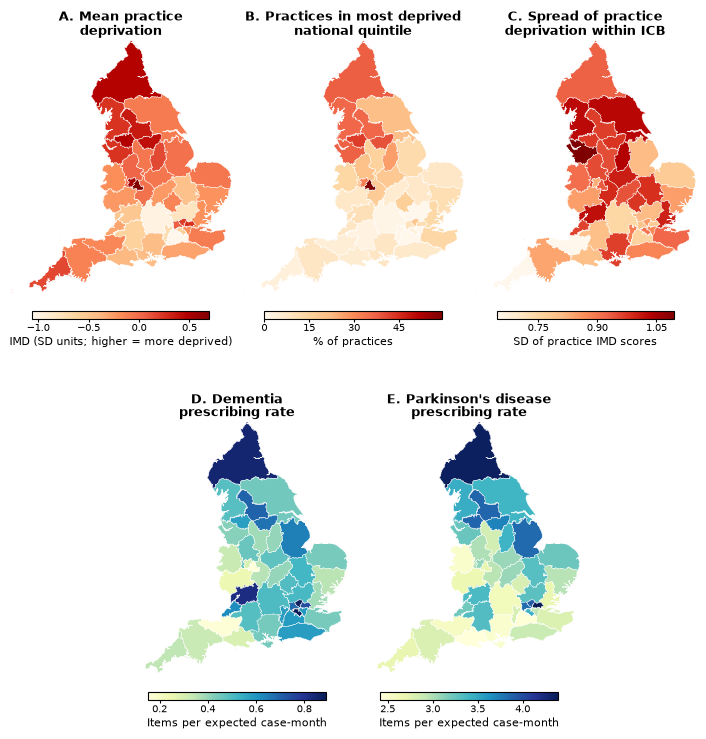

In [20]:
df_full = pd.read_parquet(FINAL_DIR / "df_full_modelling.parquet")

OUT_DIR      = FIGURES_DIR /"Choropleth_maps"
BOUNDARY_PATH = RAW_DIR / "GeoJSON" / "icb_boundaries_april_2023_bsc.geojson"
LOOKUP_PATH   = RAW_DIR / "GeoJSON" / "lsoa2021_sicbl_icb_lad_april_2023_lookup.geojson"
DRUG_GROUPS   = {"Dementia": "Dementia", "Parkinson's": "Parkinson's"}
CLIP_PCT_RATE = (2, 98)


FIG_W         = 7.0  
DPI           = 300
TITLE_FS, LABEL_FS, TICK_FS = 9, 8, 7

gdf = gpd.read_file(BOUNDARY_PATH)[["ICB23CD", "geometry"]]
lk = gpd.read_file(LOOKUP_PATH, ignore_geometry=True)[["ICB23CD", "ICB23CDH"]].drop_duplicates()
gdf = gdf.merge(lk, on="ICB23CD", how="left")
GEO_CODE = "ICB23CDH"
gdf[GEO_CODE] = gdf[GEO_CODE].astype(str).str.strip().str.upper()
gdf = gdf.to_crs(27700).reset_index(drop=True)

d = df_full.copy()
d["ICB_CODE"] = d["ICB_CODE"].astype(str).str.strip().str.upper()

pr = (d.groupby(["ICB_CODE", "PRACTICE_CODE"], observed=True).agg(imd=("imd25_scaled", "first")).reset_index())
pr["quintile"] = pd.qcut(pr["imd"], 5, labels=False) + 1
icb = pr.groupby("ICB_CODE").agg(mean_imd=("imd", "mean"), sd_imd=("imd", "std"))
icb["share_q5"] = 100 * (pr["quintile"] == 5).groupby(pr["ICB_CODE"]).mean()

rates = {}
for title, grp in DRUG_GROUPS.items():
    x = d[d["DRUG_GROUP"].astype(str) == grp]
    pm = (x.groupby(["ICB_CODE", "PRACTICE_CODE", "YEAR_MONTH_DATE"], observed=True)
            .agg(items=("ITEMS", "sum"), exp=("EXPECTED_CASES", "first")).reset_index())
    s_ = pm.groupby("ICB_CODE").agg(items=("items", "sum"), exp=("exp", "sum"))
    rates[title] = s_["items"] / s_["exp"]
for name, ser in [("deprivation", icb["mean_imd"]), *rates.items()]:
    print(f"{name}: matched {ser.index.isin(gdf[GEO_CODE]).sum()} of {len(ser)} ICBs")

def patches(geom):
    polys = [geom] if geom.geom_type == "Polygon" else list(geom.geoms)
    out = []
    for p in polys:
        verts, codes = [], []
        for ring in [p.exterior, *p.interiors]:
            xy = np.asarray(ring.coords)
            verts += list(xy)
            codes += [MPath.MOVETO] + [MPath.LINETO] * (len(xy) - 2) + [MPath.CLOSEPOLY]
        out.append(PathPatch(MPath(verts, codes)))
    return out

# ---------- panels ----------
panels = [
    ("A. Mean practice\ndeprivation",                    icb["mean_imd"], "OrRd",
     "IMD (SD units; higher = more deprived)",           None,           (0, slice(0, 2))),
    ("B. Practices in most deprived\nnational quintile", icb["share_q5"], "OrRd",
     "% of practices",                                   None,           (0, slice(2, 4))),
    ("C. Spread of practice\ndeprivation within ICB",    icb["sd_imd"],   "OrRd",
     "SD of practice IMD scores",                        None,           (0, slice(4, 6))),
    ("D. Dementia\nprescribing rate",                    rates["Dementia"],    "YlGnBu",
     "Items per expected case-month",                    CLIP_PCT_RATE,  (1, slice(1, 3))),
    ("E. Parkinson's disease\nprescribing rate",         rates["Parkinson's"], "YlGnBu",
     "Items per expected case-month",                    CLIP_PCT_RATE,  (1, slice(3, 5))),
]

minx, miny, maxx, maxy = gdf.total_bounds
aspect = (maxy - miny) / (maxx - minx)
panel_w = FIG_W / 3
panel_h = panel_w * aspect
fig = plt.figure(figsize=(FIG_W, 2 * (panel_h + 0.95)), facecolor="white")
gs = fig.add_gridspec(2, 6, wspace=0.10, hspace=0.38, left=0.01, right=0.99, top=0.95, bottom=0.04)

for title, ser, cm_name, label, clip, (r, cols) in panels:
    ax = fig.add_subplot(gs[r, cols])
    cmap = mpl.colormaps[cm_name]
    g = gdf.merge(ser.rename("val"), left_on=GEO_CODE, right_index=True, how="left")
    vmin, vmax = (np.nanpercentile(g["val"], clip) if clip else (g["val"].min(), g["val"].max()))
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax, clip=True)
    for geom, val in zip(g.geometry, g["val"]):
        colour = "#DDDDDD" if pd.isna(val) else cmap(norm(val))
        ax.add_collection(PatchCollection(patches(geom), facecolor=colour, edgecolor="white", linewidth=0.3))
    ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=TITLE_FS, fontweight="bold", loc="center", pad=4, linespacing=1.15)
    cax = ax.inset_axes([0.10, -0.10, 0.80, 0.03])
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal")
    cb.ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
    cb.set_label(label, fontsize=LABEL_FS, labelpad=2)
    cb.ax.tick_params(labelsize=TICK_FS, length=2, pad=1.5)

fig.savefig(f"{OUT_DIR}.png", dpi=DPI, bbox_inches="tight", facecolor="white")
fig.savefig(f"{OUT_DIR}.pdf", bbox_inches="tight", facecolor="white")
plt.show()

# Primary model

In [21]:
OUT_GROUPS = TABLES_DIR / "Primary_NB2_all_covariates_groups.tex"
OUT_SUBS   = TABLES_DIR / "Primary_NB2_all_covariates_substances.tex"

DECIMALS = 3
FONT     = r"\footnotesize"     # \scriptsize, \footnotesize, \small
STRETCH  = 1.0                  # row spacing
COLSEP   = "4pt"                # gap between columns
MARGIN   = "0cm"                # extend into each margin (e.g. "1.5cm"); needs changepage
HEIGHT   = r"0.85\textheight"   # table shrinks to fit this height
LANDSCAPE_GROUPS = False        # True wraps the table in landscape (needs pdflscape)
LANDSCAPE_SUBS   = True
STRUT = r"\rule[-1.4ex]{0pt}{3.8ex}"   # equal row heights
RAISE = "0.8ex"                         # centres names beside two-line cells

CAPTION_GROUPS = "Associations between practice-level covariates and prescribing, by disease and drug class"
CAPTION_SUBS   = "Associations between practice-level covariates and prescribing, by individual substance"
LABEL_GROUPS, LABEL_SUBS = "tab:results_all_covariates_groups", "tab:results_all_covariates_substances"

# (outcome, term or VPC column, header, group header)
COLUMNS = [
    ("any", "imd25_scaled",        "IMD25",            "Any prescribing (OR)"),
    ("any", "rural",               "Rural",            "Any prescribing (OR)"),
    ("any", "gpfte_practice_mean", "GP FTE (between)", "Any prescribing (OR)"),
    ("any", "gpfte_within",        "GP FTE (within)",  "Any prescribing (OR)"),
    ("vol", "imd25_scaled",        "IMD25",            "Volume (IRR)"),
    ("vol", "rural",               "Rural",            "Volume (IRR)"),
    ("vol", "gpfte_practice_mean", "GP FTE (between)", "Volume (IRR)"),
    ("vol", "gpfte_within",        "GP FTE (within)",  "Volume (IRR)"),
    ("vol", "VPC_practice",        "Practice",         "VPC (volume)"),
    ("vol", "VPC_icb",             "ICB",              "VPC (volume)"),
]
OUTCOMES = {"any": ("Zero", "Zero part (P(zero))", True),   # zero part is P(zero): invert for "any prescribing"
            "vol": ("Volume", "Volume", False)}

NOTE = (r"{\footnotesize \textit{Notes:} Estimates are per 1 SD increase in IMD25 (higher = more deprived), per 1 SD in GP FTE per 1,000 patients "
        r"(between practices, and within-practice deviation from the practice mean), and for rural versus urban practices. "
        r"Any prescribing (OR) is the odds of any prescribing in a practice-month; Volume (IRR) is the rate ratio for items per expected case "
        r"among practice-months with any prescribing. 95\% confidence intervals in brackets. "
        r"$^{*}p<0.05$, $^{**}p<0.01$, $^{***}p<0.001$. VPC is the share of latent variance in volume at each level. -- = not estimated.\par}")

# (label, level, name, tier): tier 0 = disease, 1 = drug class, 2 = substance
layout = [
 ("Dementia", "disease", "Dementia", 0),
 ("AChEIs", "drug_type", "AChEI", 1),
 ("Donepezil", "individual", "Donepezil", 2),
 ("Galantamine", "individual", "Galantamine", 2),
 ("Rivastigmine", "individual", "Rivastigmine", 2),
 ("NMDA receptor antagonists (memantine)", "drug_type", "DEM_NDMA_Receptor_Agonists", 1),
 ("Parkinson's disease", "disease", "Parkinsons", 0),
 ("Anticholinergics", "drug_type", "Anticholinergic", 1),
 ("Benzatropine", "individual", "Benzatropine", 2),
 ("Biperiden", "individual", "Biperiden", 2),
 ("Trihexyphenidyl", "individual", "Trihexyphenidyl", 2),
 ("Procyclidine", "individual", "Procyclidine", 2),
 ("Orphenadrine", "individual", "Orphenadrine", 2),
 ("Dopamine precursors", "drug_type", "Dopamine_Precursor", 1),
 ("Co-beneldopa", "individual", "Co_beneldopa", 2),
 ("Co-careldopa", "individual", "Co_careldopa", 2),
 ("Levodopa/carbidopa/entacapone", "individual", "Levodopa_carbidopa_entacapone", 2),
 ("Levodopa", "individual", "Levodopa", 2),
 ("Carbidopa", "individual", "Carbidopa", 2),
 ("Dopamine agonists", "drug_type", "Dopamine_Agonists", 1),
 ("Cabergoline", "individual", "Cabergoline", 2),
 ("Apomorphine", "individual", "Apomorphine", 2),
 ("Pramipexole", "individual", "Pramipexole", 2),
 ("Ropinirole", "individual", "Ropinirole", 2),
 ("Rotigotine", "individual", "Rotigotine", 2),
 ("COMT inhibitors", "drug_type", "COMT_Inhibitors", 1),
 ("Entacapone", "individual", "Entacapone", 2),
 ("Opicapone", "individual", "Opicapone", 2),
 ("Tolcapone", "individual", "Tolcapone", 2),
 ("MAO-B inhibitors", "drug_type", "MAOB_Inhibitors", 1),
 ("Rasagiline", "individual", "Rasagiline", 2),
 ("Safinamide", "individual", "Safinamide", 2),
 ("Selegiline", "individual", "Selegiline", 2),
 ("NMDA receptor antagonists (amantadine)", "drug_type", "PD_NDMA_Receptor_Agonists", 1),
]

# ===================== CODE =====================
def esc(s):
    return str(s).replace("&", r"\&").replace("%", r"\%").replace("#", r"\#").replace("_", r"\_")

def stars(p):
    s = "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""
    return rf"\textsuperscript{{{s}}}" if s else ""

_cache = {}
def load(level):
    if level not in _cache:
        d = MODEL_DIR / level
        files = [p for p in d.glob("*results*.xlsx") if not p.name.startswith("~$")] if d.exists() else []
        if not files:
            raise FileNotFoundError(level)
        f = max(files, key=lambda p: p.stat().st_mtime)
        print(f"{level}: using {f.name}")
        _cache[level] = (pd.read_excel(f, sheet_name="coefficients"), pd.read_excel(f, sheet_name="variance_vpc"))
    return _cache[level]

def cell(level, name, outcome, key):
    coefs, vpc = load(level)
    prefix, vpc_part, flip = OUTCOMES[outcome]
    if key.startswith("VPC"):
        v = vpc[(vpc["name"] == name) & (vpc["part"] == vpc_part)]
        return (f"{v[key].iloc[0]:.{DECIMALS}f}", "") if len(v) and pd.notna(v[key].iloc[0]) else ("--", "")
    x = coefs[(coefs["name"] == name) & coefs["part"].str.startswith(prefix) & (coefs["term"] == key)]
    if x.empty:
        return "--", ""
    r = x.iloc[0]
    sgn = -1 if flip else 1
    e = np.exp(sgn * r["estimate"])
    lo, hi = sorted([np.exp(sgn * r["estimate"] - 1.96 * r["se"]), np.exp(sgn * r["estimate"] + 1.96 * r["se"])])
    return f"{e:.{DECIMALS}f}{stars(r['p'])}", rf"{{\scriptsize [{lo:.{DECIMALS}f}, {hi:.{DECIMALS}f}]}}"

def fmt(text, ci):
    return rf"\shortstack[c]{{{text}\\{ci}}}" if ci else text

def build(rows, out_file, caption, label, bold_tiers, landscape):
    n = len(COLUMNS)
    groups, i = [], 0
    while i < n:
        j = i
        while j + 1 < n and COLUMNS[j + 1][3] == COLUMNS[i][3]:
            j += 1
        groups.append((COLUMNS[i][3], i, j)); i = j + 1

    L = [r"\begin{landscape}"] if landscape else []
    L += [r"\begin{table}[htbp]", r"\centering", rf"\caption{{{caption}}}", rf"\label{{{label}}}",
          FONT, rf"\renewcommand{{\arraystretch}}{{{STRETCH}}}", rf"\setlength{{\tabcolsep}}{{{COLSEP}}}",
          rf"\begin{{adjustwidth}}{{-{MARGIN}}}{{-{MARGIN}}}",
          rf"\begin{{adjustbox}}{{max totalsize={{\linewidth}}{{{HEIGHT}}}}}",
          rf"\begin{{tabular}}{{l{'c' * n}}}", r"\toprule"]
    cells, rules = [""], []
    for g, a, b in groups:
        cells.append(rf"\multicolumn{{{b - a + 1}}}{{c}}{{{g}}}")
        rules.append(rf"\cmidrule(lr){{{a + 2}-{b + 2}}}")
    L += [" & ".join(cells) + r" \\", "".join(rules),
          " & ".join(["Substance / group"] + [h for _, _, h, _ in COLUMNS]) + r" \\", r"\midrule"]

    for idx, (lab, level, name, tier) in enumerate(rows):
        if tier == 0 and idx > 0:
            L.append(r"\midrule")
        try:
            vals = [fmt(*cell(level, name, o, k)) for o, k, _, _ in COLUMNS]
        except FileNotFoundError:
            vals = ["--"] * n
        has_est = any("shortstack" in v for v in vals)
        txt = rf"\textbf{{{esc(lab)}}}" if tier in bold_tiers else esc(lab)
        nm = rf"\hspace{{{tier}em}}\raisebox{{{RAISE if has_est else '0ex'}}}{{{txt}}}{STRUT}"
        L.append(" & ".join([nm] + vals) + r" \\")

    L += [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{adjustwidth}",
          r"\par\vspace{4pt}", NOTE, r"\end{table}"]
    if landscape:
        L.append(r"\end{landscape}")
    out_file.write_text("\n".join(L) + "\n")
    print("Saved:", out_file)

# Table 1: disease and drug class only (diseases bold)
build([r for r in layout if r[3] in (0, 1)], OUT_GROUPS, CAPTION_GROUPS, LABEL_GROUPS,
      bold_tiers={0}, landscape=LANDSCAPE_GROUPS)
# Substance table: groups as bold headings with their estimates, substances indented beneath
build(layout, OUT_SUBS, CAPTION_SUBS, LABEL_SUBS, bold_tiers={0, 1}, landscape=LANDSCAPE_SUBS)

print(r"\input{tables/results_Primary_NB2_all_covariates_groups.tex}")
print(r"\input{tables/results_Primary_NB2_all_covariates_substances.tex}")

disease: using NB2_disease_results.xlsx
drug_type: using NB2_drug_type_results.xlsx
Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/Primary_NB2_all_covariates_groups.tex
individual: using NB2_individual_results.xlsx
Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/Primary_NB2_all_covariates_substances.tex
\input{tables/results_Primary_NB2_all_covariates_groups.tex}
\input{tables/results_Primary_NB2_all_covariates_substances.tex}


# Sensitivy Tables

In [22]:
LANDSCAPE_SENS = False   
ROOT   = BASE_DIR / "Models"
STAR   = r"$^{*}p<0.05$, $^{**}p<0.01$, $^{***}p<0.001$."
CISTAR = r"$^{*}$ 95\% CI excludes 1 (no $p$-values saved for this check)."
note   = lambda t: r"{\footnotesize \textit{Notes:} " + t + r"\par}"
num    = lambda v, d=0: f"{v:,.{d}f}".replace("-", "$-$")
DRUG   = [r for r in layout if r[1] == "drug_type"]

_mc = {}
def loadm(model, level):
    """All sheets of the newest results workbook for a model set and level (None if missing)."""
    if (model, level) not in _mc:
        d = ROOT / model / level
        fs = [p for p in d.glob("*results*.xlsx") if not p.name.startswith("~$")] if d.exists() else []
        _mc[(model, level)] = None if not fs else pd.read_excel(max(fs, key=lambda p: p.stat().st_mtime), sheet_name=None)
    return _mc[(model, level)]

def converged(sh, name):
    if sh is None: return False
    x = sh["diagnostics_post"].loc[sh["diagnostics_post"]["name"] == name, "pdHess"]
    return bool(len(x) and x.iloc[0] == True)

def ratio_cell(est, lo, hi, p=None, dag=False):
    if est is None or pd.isna(est): return "--", ""
    s = stars(p) if (p is not None and pd.notna(p)) else (r"\textsuperscript{*}" if (lo > 1 or hi < 1) else "")
    if dag: s += r"\textsuperscript{\dag}"
    return f"{est:.{DECIMALS}f}{s}", rf"{{\scriptsize [{lo:.{DECIMALS}f}, {hi:.{DECIMALS}f}]}}"

def from_log(est, se, p=None, sgn=1):
    a, b = sorted([np.exp(sgn * est - 1.96 * se), np.exp(sgn * est + 1.96 * se)])
    return ratio_cell(np.exp(sgn * est), a, b, p)

def coef_cell(sh, name, outcome, term="imd25_scaled"):
    if sh is None: return "--", ""
    c = sh["coefficients"]; prefix, _, flip = OUTCOMES[outcome]
    x = c[(c["name"] == name) & c["part"].str.startswith(prefix) & (c["term"] == term)]
    if x.empty: return "--", ""
    r = x.iloc[0]
    return from_log(r["estimate"], r["se"], r["p"], -1 if flip else 1)

def build_cmp(rows, columns, getter, out_file, caption, label, nt, flat=False, bold=(0, 1)):
    """columns = [(key, header, group_header)]; getter(level, name, key) -> (text, ci)."""
    n = len(columns)
    groups, i = [], 0
    while i < n:
        j = i
        while j + 1 < n and columns[j + 1][2] == columns[i][2]: j += 1
        groups.append((columns[i][2], i, j)); i = j + 1
    L = [r"\begin{landscape}"] if LANDSCAPE_SENS else []
    L += [r"\begin{table}[htbp]", r"\centering", rf"\caption{{{caption}}}", rf"\label{{{label}}}",
          FONT, rf"\renewcommand{{\arraystretch}}{{{STRETCH}}}", rf"\setlength{{\tabcolsep}}{{{COLSEP}}}",
          rf"\begin{{adjustwidth}}{{-{MARGIN}}}{{-{MARGIN}}}",
          rf"\begin{{adjustbox}}{{max totalsize={{\linewidth}}{{{HEIGHT}}}}}",
          rf"\begin{{tabular}}{{l{'c' * n}}}", r"\toprule"]
    cells, rules = [""], []
    for g, a, b in groups:
        cells.append(rf"\multicolumn{{{b - a + 1}}}{{c}}{{{g}}}")
        rules.append(rf"\cmidrule(lr){{{a + 2}-{b + 2}}}")
    L += [" & ".join(cells) + r" \\", "".join(rules),
          " & ".join(["Substance / group"] + [h for _, h, _ in columns]) + r" \\", r"\midrule"]
    for idx, (lab, level, name, tier) in enumerate(rows):
        if not flat and tier == 0 and idx > 0: L.append(r"\midrule")
        vals = [fmt(*getter(level, name, k)) for k, _, _ in columns]
        has_est = any("shortstack" in v for v in vals)
        t = esc(lab)
        if not flat and tier in bold: t = rf"\textbf{{{t}}}"
        nm = rf"\hspace{{{0 if flat else tier}em}}\raisebox{{{RAISE if has_est else '0ex'}}}{{{t}}}{STRUT}"
        L.append(" & ".join([nm] + vals) + r" \\")
    L += [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{adjustwidth}", r"\par\vspace{4pt}", nt, r"\end{table}"]
    if LANDSCAPE_SENS: L.append(r"\end{landscape}")
    out_file.write_text("\n".join(L) + "\n"); print("Saved:", out_file)

## NB1

In [23]:
OUT_IMD = TABLES_DIR / "results_Primary_NB2_imd_full.tex"
OUT_COV = TABLES_DIR / "results_Primary_NB2_covariates_full.tex"
LANDSCAPE_IMD, LANDSCAPE_COV = False, False   # needs pdflscape
BOLD = {0, 1}                                  # bold disease and drug class rows

COLS_IMD = [("any", "imd25_scaled", "IMD25",    "Any prescribing (OR)"),
            ("vol", "imd25_scaled", "IMD25",    "Volume (IRR)"),
            ("vol", "VPC_practice", "Practice", "VPC (volume)"),
            ("vol", "VPC_icb",      "ICB",      "VPC (volume)")]
COLS_COV = [("any", "rural",               "Rural",            "Any prescribing (OR)"),
            ("any", "gpfte_practice_mean", "GP FTE (between)", "Any prescribing (OR)"),
            ("any", "gpfte_within",        "GP FTE (within)",  "Any prescribing (OR)"),
            ("vol", "rural",               "Rural",            "Volume (IRR)"),
            ("vol", "gpfte_practice_mean", "GP FTE (between)", "Volume (IRR)"),
            ("vol", "gpfte_within",        "GP FTE (within)",  "Volume (IRR)")]

STAR = r"$^{*}p<0.05$, $^{**}p<0.01$, $^{***}p<0.001$."
OUTC = (r"Any prescribing (OR) is the odds of any prescribing in a practice-month; Volume (IRR) is the rate ratio for items per expected case "
        r"among practice-months with any prescribing. 95\% confidence intervals in brackets. ")
NOTE_IMD = (r"{\footnotesize \textit{Notes:} Estimates are per 1 SD increase in IMD25 (higher = more deprived), adjusted for the covariates in Table~\ref{tab:results_all_covariates_substances}. "
            + OUTC + STAR + r" VPC is the share of latent variance in volume at each level. -- = not estimated.\par}")
NOTE_COV = (r"{\footnotesize \textit{Notes:} Estimates are from the same models as the IMD25 table. Rural is rural versus urban practice; GP FTE (between) is the practice mean "
            r"GP FTE per 1,000 patients and GP FTE (within) is the deviation from that mean, both per 1 SD. "
            + OUTC + STAR + r" -- = not estimated.\par}")

def build_full(columns, out_file, caption, label, note, landscape):
    n = len(columns)
    groups, i = [], 0
    while i < n:
        j = i
        while j + 1 < n and columns[j + 1][3] == columns[i][3]:
            j += 1
        groups.append((columns[i][3], i, j)); i = j + 1
    L = [r"\begin{landscape}"] if landscape else []
    L += [r"\begin{table}[htbp]", r"\centering", rf"\caption{{{caption}}}", rf"\label{{{label}}}",
          FONT, rf"\renewcommand{{\arraystretch}}{{{STRETCH}}}", rf"\setlength{{\tabcolsep}}{{{COLSEP}}}",
          rf"\begin{{adjustwidth}}{{-{MARGIN}}}{{-{MARGIN}}}",
          rf"\begin{{adjustbox}}{{max totalsize={{\linewidth}}{{{HEIGHT}}},center}}",
          rf"\begin{{tabular}}{{l{'c' * n}}}", r"\toprule"]
    cells, rules = [""], []
    for g, a, b in groups:
        cells.append(rf"\multicolumn{{{b - a + 1}}}{{c}}{{{g}}}")
        rules.append(rf"\cmidrule(lr){{{a + 2}-{b + 2}}}")
    L += [" & ".join(cells) + r" \\", "".join(rules),
          " & ".join(["Substance / group"] + [h for _, _, h, _ in columns]) + r" \\", r"\midrule"]
    for idx, (lab, level, name, tier) in enumerate(layout):
        if tier == 0 and idx > 0:
            L.append(r"\midrule")
        try:
            vals = [fmt(*cell(level, name, o, k)) for o, k, _, _ in columns]
        except FileNotFoundError:
            vals = ["--"] * n
        has_est = any("shortstack" in v for v in vals)
        txt = rf"\textbf{{{esc(lab)}}}" if tier in BOLD else esc(lab)
        nm = rf"\hspace{{{tier}em}}\raisebox{{{RAISE if has_est else '0ex'}}}{{{txt}}}{STRUT}"
        L.append(" & ".join([nm] + vals) + r" \\")
    L += [r"\bottomrule", r"\end{tabular}", r"\end{adjustbox}", r"\end{adjustwidth}", r"\par\vspace{4pt}", note, r"\end{table}"]
    if landscape:
        L.append(r"\end{landscape}")
    out_file.write_text("\n".join(L) + "\n")
    print("Saved:", out_file)

build_full(COLS_IMD, OUT_IMD,
           "Association between practice-level deprivation and prescribing, by disease, drug class and substance",
           "tab:results_imd_full", NOTE_IMD, LANDSCAPE_IMD)
build_full(COLS_COV, OUT_COV,
           "Associations between rurality, GP workforce and prescribing, by disease, drug class and substance",
           "tab:results_covariates_full", NOTE_COV, LANDSCAPE_COV)

print(r"\input{TexFilesTables/results_Primary_NB2_imd_full.tex}")
print(r"\input{TexFilesTables/results_Primary_NB2_covariates_full.tex}")

Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/results_Primary_NB2_imd_full.tex
Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/results_Primary_NB2_covariates_full.tex
\input{TexFilesTables/results_Primary_NB2_imd_full.tex}
\input{TexFilesTables/results_Primary_NB2_covariates_full.tex}


## AR(1)

In [24]:
def get_ar1(level, name, key):
    P, A = loadm("Primary_NB2", level), loadm("AR1_NB2", level)
    if key == "irr_p": return coef_cell(P, name, "vol")
    if A is None or name not in set(A["diagnostics_post"]["name"]): return "--", ""
    if not converged(A, name): return "n/c", ""
    if key == "irr_a": return coef_cell(A, name, "vol")
    if key == "rho":
        v = A["variance_vpc"]; x = v[(v["name"] == name) & (v["part"] == "Volume")]
        return (f"{x['ar1_rho'].iloc[0]:.3f}", "") if len(x) else ("--", "")
    if key == "daic":
        a = A["diagnostics_post"].set_index("name")["AIC"]; p = P["diagnostics_post"].set_index("name")["AIC"]
        return num(a[name] - p[name]), ""

build_cmp(DRUG, [("irr_p", "Primary", "Volume (IRR)"), ("irr_a", "AR(1)", "Volume (IRR)"),
                 ("rho", r"$\rho$", "AR(1) model"), ("daic", r"$\Delta$AIC", "AR(1) model")],
          get_ar1, TABLES_DIR / "results_sens_ar1.tex",
          "Sensitivity analysis: IMD25 association with an AR(1) practice-level error structure, by drug class",
          "tab:sens_ar1",
          note(r"Volume IRRs per 1 SD increase in IMD25 from the primary NB2 model and the model with an added practice-level AR(1) term (count part only, "
               r"so the odds of any prescribing are unchanged). $\rho$ is the estimated AR(1) correlation; $\Delta$AIC is AR(1) minus primary (negative = better fit). "
               r"n/c = did not converge. 95\% CIs in brackets. " + STAR), flat=True)

Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/results_sens_ar1.tex


## Offset proportionallity

In [26]:
OFF = ROOT / "Offset_Proportionality" / "Offset_Proportionality.xlsx"
off = pd.read_excel(OFF, sheet_name="offset_test").set_index(["level", "name"])
cov = pd.read_excel(OFF, sheet_name="covariate_change"); cov = cov[cov["term"] == "imd25_scaled"].set_index(["level", "name"])

def get_off(level, name, key):
    k = (level, name)
    if k not in off.index or k not in cov.index: return "--", ""
    o, c = off.loc[k], cov.loc[k]
    if not (o["pdHess_offset"] and o["pdHess_free"]): return "n/c", ""
    if key == "irr_o": return from_log(c["est_offset_only"], c["se_offset_only"], c["p_offset_only"])
    if key == "irr_f": return from_log(c["est_free_covariate"], c["se_free_covariate"], c["p_free_covariate"])
    if key == "elast":
        return (f"{o['elasticity']:.{DECIMALS}f}{stars(o['p_LRT'])}",
                rf"{{\scriptsize [{o['ci_lo']:.{DECIMALS}f}, {o['ci_hi']:.{DECIMALS}f}]}}")
    if key == "daic": return num(o["dAIC_free_minus_offset"], 1), ""

build_cmp(layout, [("irr_o", "Offset (primary)", "Volume (IRR), IMD25"), ("irr_f", "Free term", "Volume (IRR), IMD25"),
                   ("elast", "Elasticity", "Offset test"), ("daic", r"$\Delta$AIC", "Offset test")],
          get_off, TABLES_DIR / "results_sens_offset.tex",
          "Sensitivity analysis: offset replaced by a freely estimated log expected-cases term",
          "tab:sens_offset",
          note(r"Volume IRRs per 1 SD increase in IMD25 with expected cases as an offset (primary) and as a free covariate (fitted to positive months only). "
               r"Elasticity is the coefficient on log expected cases (1 = proportional); its stars are from a likelihood-ratio test against 1. "
               r"$\Delta$AIC is free term minus offset (negative = better fit). n/c = a fit did not converge. 95\% CIs in brackets. " + STAR))

Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/results_sens_offset.tex


## Without rurality/GP FTE

In [30]:
def make_drop_getter(tag):
    d = pd.read_excel(ROOT / "Covariate_Sensitivity" / tag / f"sensitivity_without_{tag}_ALL.xlsx", sheet_name="ALL")
    full = d[d["dropped"] == "none"].set_index(["level", "name"]); red = d[d["dropped"] != "none"].set_index(["level", "name"])
    cols = {"or": ("OR_any", "OR_lo", "OR_hi"), "irr": ("IRR", "IRR_lo", "IRR_hi")}
    def g(level, name, key):
        out, which = key.split("_"); k = (level, name)
        src = full if which == "f" else red
        if k not in src.index: return "--", ""
        r = src.loc[k]
        if which == "r" and not r["pdHess"]: return "n/c", ""
        e, lo, hi = cols[out]
        return ratio_cell(r[e], r[lo], r[hi])
    return g

for tag, lab, cap, label in [("rural", "Without rurality", "rurality", "tab:sens_drop_rural"),
                             ("gpfte_between", "Without GP FTE (between)", "between-practice GP FTE", "tab:sens_drop_gpfte")]:
    build_cmp(layout, [("or_f", "Primary", "Any prescribing (OR)"), ("or_r", lab, "Any prescribing (OR)"),
                       ("irr_f", "Primary", "Volume (IRR)"), ("irr_r", lab, "Volume (IRR)")],
              make_drop_getter(tag), TABLES_DIR / f"results_sens_drop_{tag}.tex",
              f"Sensitivity analysis: IMD25 association when {cap} is omitted", label,
              note(rf"Odds of any prescribing (OR) and volume rate ratios (IRR) per 1 SD increase in IMD25 from the primary model and the model omitting {cap}. "
                   r"n/c = did not converge; 95\% CIs in brackets. " + CISTAR))

Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/results_sens_drop_rural.tex
Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/results_sens_drop_gpfte_between.tex


## Without Decile

In [31]:
DEC_FIT = "decile, linear (per decile)"     # or "decile, linear (decile 10 vs 1)"
dd = pd.read_excel(ROOT / "IMD_Decile_Sensitivity" / "imd_decile_sensitivity_ALL.xlsx", sheet_name="ALL")
def get_dec(level, name, key):
    out, which = key.split("_")
    m = dd["fit"].str.startswith("primary") if which == "p" else (dd["fit"] == DEC_FIT)
    x = dd[(dd["level"] == level) & (dd["name"] == name) & m]
    if x.empty: return "--", ""
    r = x.iloc[0]
    if which == "d" and r["pdHess"] != True: return "n/c", ""
    e, lo, hi = {"or": ("OR_any", "OR_lo", "OR_hi"), "irr": ("IRR", "IRR_lo", "IRR_hi")}[out]
    return ratio_cell(r[e], r[lo], r[hi])

build_cmp(layout, [("or_p", "Per 1 SD", "Any prescribing (OR)"), ("or_d", "Per decile", "Any prescribing (OR)"),
                   ("irr_p", "Per 1 SD", "Volume (IRR)"), ("irr_d", "Per decile", "Volume (IRR)")],
          get_dec, TABLES_DIR / "results_sens_decile.tex",
          "Sensitivity analysis: IMD25 score replaced by IMD decile", "tab:sens_decile",
          note(r"Primary estimates are per 1 SD of the continuous IMD25 score; sensitivity estimates are per decile (10 = most deprived), "
               r"so sizes are not directly comparable and direction and significance are the point of comparison. n/c = did not converge. 95\% CIs in brackets. " + CISTAR))

Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/results_sens_decile.tex


## Correlated brms

In [32]:
br = pd.read_excel(ROOT / "Correlated_RE_brms" / "correlated_re_brms_ALL.xlsx", sheet_name="results")
def get_brms(level, name, key):
    x = br[br["name"] == name]
    if x.empty or pd.isna(x.iloc[0].get("IRR")): return "--", ""
    r = x.iloc[0]
    conv = max(r["rhat_IRR"], r["rhat_OR"], r["rhat_rho"]) < 1.01 and min(r["ess_IRR"], r["ess_OR"], r["ess_rho"]) > 400 and r["divergences"] == 0
    if key == "irr_i": return ratio_cell(r["IRR_ind"], r["IRR_ind_lo"], r["IRR_ind_hi"])
    if key == "irr_c": return ratio_cell(r["IRR"], r["IRR_lo"], r["IRR_hi"], dag=not conv)
    if key == "or_i":  return ratio_cell(r["OR_ind"], r["OR_ind_lo"], r["OR_ind_hi"])
    if key == "or_c":  return ratio_cell(r["OR_any"], r["OR_lo"], r["OR_hi"], dag=not conv)
    if key == "rho":   return f"{r['rho']:.2f}", rf"{{\scriptsize [{r['rho_lo']:.2f}, {r['rho_hi']:.2f}]}}"

build_cmp(DRUG, [("or_i", "Independent", "Any prescribing (OR)"), ("or_c", "Correlated", "Any prescribing (OR)"),
                 ("irr_i", "Independent", "Volume (IRR)"), ("irr_c", "Correlated", "Volume (IRR)"),
                 ("rho", r"$\rho$", "Stage correlation")],
          get_brms, TABLES_DIR / "results_sens_brms.tex",
          "Sensitivity analysis: correlated count- and zero-stage practice intercepts (Bayesian, 300-practice sample)", "tab:sens_brms",
          note(r"IMD25 estimates per 1 SD from independent-stage (glmmTMB) and correlated-stage (brms) hurdle models fitted to the same random sample of 300 practices. "
               r"Correlated estimates are posterior means with 95\% credible intervals; $\rho$ is the count-zero practice intercept correlation. "
               r"$^{\dag}$ R-hat, effective sample size or divergence criteria not met. -- = not fitted (under 1\% zeros or not run). $^{*}$ 95\% interval excludes 1."), flat=True)

Saved: /Users/trinityrose/Desktop/NDD_Prescribing/Tables/results_sens_brms.tex
